<font size = 3 color="gray">Máster Universitario en inteligencia artificial (MUIA)</font>  

# Peceptron de Rosenblatt

Ejemplo de entrenamiento de un perceptrón de Rosenblatt, para construir un clasificador binario con dos dimensiones de entrada.

## Generación del conjunto de datos

Generamos `n_samples` puntos aleatorios $(x, y)$ en el cuadrado $[-1, 1]^2$. Para crear las dos clases, trazamos una recta aleatoria $y = a \cdot x + k$ y asignamos la etiqueta $+1$ a los puntos que quedan por encima y $-1$ a los que quedan por debajo. A continuación desplazamos ligeramente hacia arriba los puntos de la clase positiva para garantizar un margen de separación visible entre las dos clases (controlado por `margen_seguridad`).

**Ruido en las etiquetas**: si se activa la variable `datos_no_separables = True`, se invierte al azar el 10% de las etiquetas. Esto introduce puntos que aparecen en el lado equivocado de la recta, haciendo que las clases dejen de ser linealmente separables y que el perceptrón no pueda converger a cero errores.

In [187]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# Fijamos una semilla para reproducibilidad
np.random.seed(2026)

n_samples = 200
x = np.zeros(n_samples)
y = np.zeros(n_samples)
labels = np.zeros(n_samples)
a = np.random.uniform(-2,2,1)[0]
k = np.random.uniform(-1,1,1)[0]
# Generamos muestras aleatorias entre -1 y 1
x = np.random.uniform(-1, 1,n_samples)
y = np.random.uniform(-1, 1,n_samples)
labels = y>(a*x+k)
labels = 2*labels-1
margen_seguridad = 0.1
# Subimos una cantidad muy pequeña los puntos de la categoría positiva para que haya una separación que se puede apreciar visiblemente en las gráficas
# Cuanto menor sea, más ciclos de entrenamiento son necesarios para que el perceptrón converja
y = y + margen_seguridad*(labels>0)

# Si activamos esta variable, invertimos al azar el 10% de las etiquetas,
# haciendo que el problema deje de ser linealmente separable
datos_no_separables = False
if datos_no_separables:
    n_ruido = int(0.1 * n_samples)
    idx_ruido = np.random.choice(n_samples, size=n_ruido, replace=False)
    labels[idx_ruido] = -labels[idx_ruido]

## Función auxiliar de visualización

Definimos una función reutilizable que dibuja los puntos coloreados por clase (verde = clase $+1$, naranja = clase $-1$) junto con una recta de separación dada por la ecuación $y = m \cdot x + b$. La usaremos tanto para visualizar los datos originales con su recta real como para mostrar la recta aprendida por el perceptrón.

In [188]:
def representar_muestras(x, y, labels, m, b, titulo=None):
    """Dibuja los puntos coloreados por clase y la recta y = m*x + b."""
    colores = np.where(labels == 1, 'green', 'orange')
    x_line = np.linspace(-1, 1, 100)
    y_line = m * x_line + b
    plt.scatter(x, y, c=colores, s=5)
    plt.plot(x_line, y_line)
    plt.ylim(-1, 1)
    plt.xlabel("x")
    plt.ylabel("y")
    if titulo:
        plt.title(titulo)
    plt.show()

## Visualización de los datos de entrenamiento

Representamos los puntos generados junto con la recta original $y = a \cdot x + k$ que hemos usado para separarlos. Esto nos permite comprobar visualmente que las dos clases son linealmente separables antes de entrenar el perceptrón.

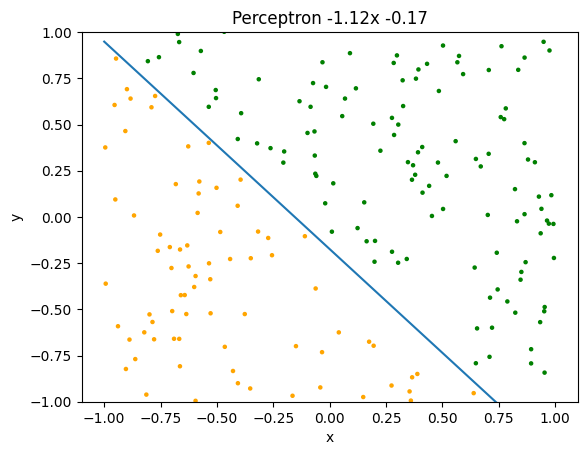

In [189]:
# Representación de las muestras de entrenamiento y de la línea que ha servido para discriminarlas
representar_muestras(x, y, labels, a, k, titulo=f"Perceptron {a:.2f}x {k:.2f}")

## Entrenamiento

### Inicialización de los pesos

El perceptrón tiene tres parámetros que debe aprender: los pesos $w_1$ (asociado a la entrada $x$) y $w_2$ (asociado a la entrada $y$), y el sesgo $b$. Los inicializamos con valores aleatorios pequeños en $[-1, 1]$. La frontera de decisión del perceptrón es la recta $w_1 \cdot x + w_2 \cdot y + b = 0$.

In [190]:
w1 = np.random.uniform(-1,1,1)
w2 = np.random.uniform(-1,1,1)
b = np.random.uniform(-1,1,1)

### Bucle de entrenamiento

En cada iteración:

1. **Predicción**: calculamos $\hat{y} = \text{sign}(w_1 \cdot x + w_2 \cdot y + b)$ para todas las muestras.
2. **Recuento de errores**: contamos cuántas predicciones no coinciden con las etiquetas reales.
3. **Selección de una muestra mal clasificada**: buscamos la primera muestra donde $\hat{y}_j \neq y_j$.
4. **Actualización de pesos** (regla del perceptrón): ajustamos cada peso en la dirección que corrige el error de esa muestra:
$$w_i \leftarrow w_i + \eta \cdot (y_j - \hat{y}_j) \cdot x_i^{(j)}, \quad b \leftarrow b + \eta \cdot (y_j - \hat{y}_j)$$

El *learning rate* $\eta$ puede decrecer exponencialmente con la proporción de errores, lo que hace que los ajustes sean más finos a medida que el modelo mejora. El bucle se ejecuta un máximo de `niter` iteraciones. Si en ese número, la solución no ha convergido, los puntos mal clasificados se aprecian con facilidad en la gráfica.

In [191]:
niter = n_samples/4
#niter=20
i=0
L=0.005
decay_rate=1
errores=n_samples
lerrores = []
while(i<niter):
    preds = np.sign(w1*x + w2*y + b)
    preds[preds == 0] = -1
    errores = np.sum(preds!=labels)
    lerrores.append(errores)
    if i%10==0:
        print(f"Iteracion {i} {errores} errores sobre {n_samples} muestras")
    # El learning rate decrece exponencialmente. Si queremos que sea constante, fijar decay_rate=0
    lr = L*np.exp(-decay_rate*(errores/n_samples))
    j = 0
    if(errores>0):
        while (preds[j]==labels[j]):
            j = j+1
        w1 = w1 + lr * (labels[j]-preds[j])*x[j]
        w2 = w2 + lr * (labels[j]-preds[j])*y[j]
        b = b + lr * (labels[j]-preds[j])
    i+=1
modelo=f"modelo calculado w1={w1[0]:.2f} w2={w2[0]:.2f} b={b[0]/w2[0]:.2f}"
print(modelo)

Iteracion 0 20 errores sobre 200 muestras
Iteracion 10 14 errores sobre 200 muestras
Iteracion 20 8 errores sobre 200 muestras
Iteracion 30 4 errores sobre 200 muestras
Iteracion 40 0 errores sobre 200 muestras
modelo calculado w1=0.76 w2=0.72 b=0.12


## Curva de aprendizaje

Representamos cómo evoluciona el número de errores de clasificación a lo largo de las iteraciones. Si el perceptrón converge correctamente, esta curva debería descender hasta llegar a cero (o cerca de cero), lo que indica que ha encontrado una recta que separa las dos clases.

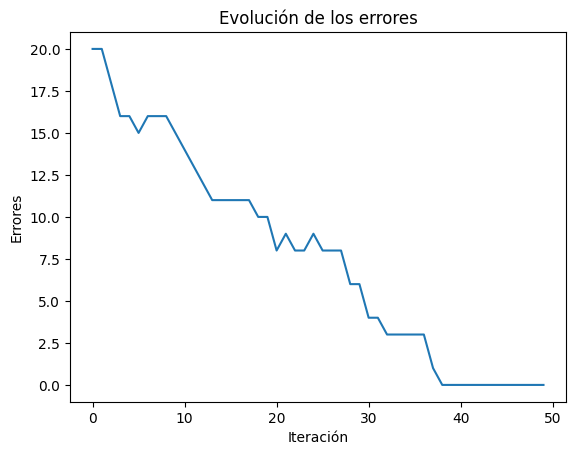

In [192]:
# Representamos la evolución del número de errores
plt.plot(range(len(lerrores)), np.array(lerrores))
plt.xlabel("Iteración")
plt.ylabel("Errores")
plt.title("Evolución de los errores")
plt.show()


## Resultado: frontera de decisión aprendida

Finalmente visualizamos los datos junto con la recta de decisión que ha aprendido el perceptrón. A partir de los pesos $w_1$, $w_2$ y $b$, la ecuación $w_1 \cdot x + w_2 \cdot y + b = 0$ se puede reescribir como:

$$y = -\frac{w_1}{w_2} \cdot x - \frac{b}{w_2}$$

Es decir, la pendiente aprendida es $m = -w_1/w_2$ y la ordenada en el origen es $-b/w_2$. Si el entrenamiento ha convergido, esta recta debería ser similar a la recta original con la que generamos los datos.

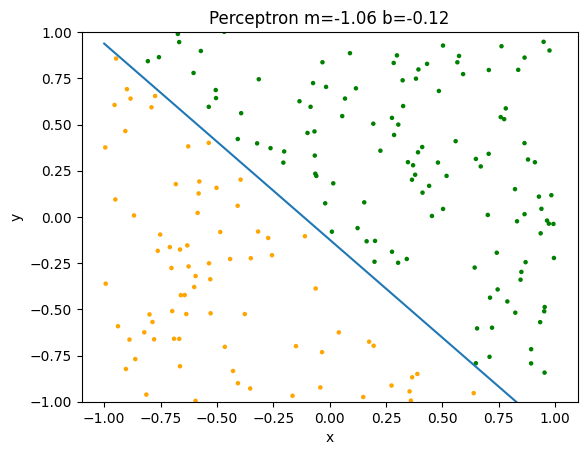

In [193]:
# Representamos las muestras y la línea de decisión: w1*x + w2*y + b = 0  →  y = -(w1/w2)*x - b/w2
m_plot = -w1[0]/w2[0]
b_plot = -b[0]/w2[0]
representar_muestras(x, y, labels, m_plot, b_plot, titulo=f"Perceptron m={m_plot:.2f} b={b_plot:.2f}")

---

<font size="1" color="grey">
    (c) 2026 Javier García Algarra. <a href='https://www.u-tad.com'>www.u-tad.com</a> <br>
Licensed under a Creative Commons Reconocimiento 4.0 Internacional License
</font>